# 4. Modéliser, et régler les hyperparamètres

**Prédiction de la qualité des soudures**

Marie Gozlan, Jules Mortreux, Grégoire Pascual, Pétronille Tard

---

## Ce que fait ce notebook

Les trois notebooks précédents ont préparé le terrain : les données sont
nettoyées, la variable à prédire est construite et justifiée, les entrées sont
préparées. Il reste à construire les modèles.

Le notebook répond à trois questions, dans cet ordre.

**Quelle famille de modèles convient à ce problème ?** Nous comparons huit
familles, de la régression linéaire au boosting, sur un protocole strictement
identique.

**Comment régler leurs hyperparamètres ?** C'est la partie la plus développée du
notebook, et volontairement. Un modèle mal réglé ne dit rien de sa famille, et
comparer des familles mal réglées ne dit rien du tout. Nous expliquons donc pour
chacune ce qu'il faut régler, pourquoi, et nous vérifions que les optima trouvés
ne sont pas au bord des plages explorées.

**Faut-il prédire le score, ou prédire les quatre propriétés puis le
recalculer ?** Le notebook 2 a signalé que le score agrégé masque la position
sur le compromis entre résistance et ductilité. Nous mesurons ici si le
décomposer coûte quelque chose. La réponse est non, et c'est même l'inverse.

## Une précision de méthode qui engage notre honnêteté

**Notre ensemble de test a été consulté trois fois au cours de l'exploration**,
dans les notebooks `05_modeles_arbres`, `06_modeles_lineaires_knn` et
`09_reentrainement_cible_y3`.

Un ensemble de test ne garde sa valeur de juge impartial que s'il sert **une
seule fois**, après que tous les choix sont arrêtés. À partir de la deuxième
consultation, les décisions prises entre-temps sont influencées par ce que l'on a
vu, et l'estimation devient optimiste.

Les chiffres de test de ces trois notebooks doivent donc être lus comme des
estimations légèrement optimistes. **Nous présentons en section 7 une évaluation
finale unique, sur le modèle définitivement retenu, et c'est la seule qui
compte.** Toutes les comparaisons qui la précèdent sont faites par validation
croisée sur le seul ensemble de développement.

In [1]:
from pathlib import Path
import json
import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.decomposition import PCA
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import (BaggingRegressor, HistGradientBoostingRegressor,
                              RandomForestRegressor)
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, ParameterGrid
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor, export_text

warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path.cwd()
while not (ROOT / "data" / "raw").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
OUT = ROOT / "outputs" / "rendu4"
OUT.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "src"))
import export_processed as nettoyage

GRAINE = 42
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10})
pd.set_option("display.max_colwidth", None)

CATEGORIES = ["AC_DC", "Electrode_pol", "WeldType"]
RESISTANCE = ["YieldStrength_MPa", "UTS_MPa"]
DUCTILITE = ["Elongation_pct", "ReductionArea_pct"]
PROPRIETES = RESISTANCE + DUCTILITE
UNITES = {"YieldStrength_MPa": "MPa", "UTS_MPa": "MPa",
          "Elongation_pct": "%", "ReductionArea_pct": "%"}
NOMS = {"YieldStrength_MPa": "limite d'élasticité",
        "UTS_MPa": "résistance à la traction",
        "Elongation_pct": "allongement",
        "ReductionArea_pct": "striction"}

donnees = pd.read_csv(ROOT / "outputs/rendu2/dataset_qualite.csv",
                      index_col="row_id",
                      dtype={c: str for c in CATEGORIES + ["WeldID", "partition"]},
                      keep_default_na=False, na_values=[""],
                      float_precision="round_trip")
VARIABLES = nettoyage.COMPOSITION + nettoyage.PROCESS
assert not set(VARIABLES) & set(PROPRIETES)

dev = donnees["partition"] == "developpement"
X_dev = donnees.loc[dev, VARIABLES]
Y_dev = donnees.loc[dev, PROPRIETES]
G_dev = donnees.loc[dev, "groupe"]

print(f"Développement : {len(X_dev)} lignes, {G_dev.nunique()} soudures.")
print(f"Test réservé  : {int((~dev).sum())} lignes, "
      f"{donnees.loc[~dev, 'groupe'].nunique()} soudures.")
print(f"{len(VARIABLES)} variables d'entrée.")

Développement : 527 lignes, 376 soudures.
Test réservé  : 123 lignes, 93 soudures.
30 variables d'entrée.


## 1. Le protocole d'évaluation

Tout est fixé une fois pour toutes, de sorte que la seule chose qui varie entre
deux lignes d'un tableau soit ce que ce tableau compare.

**Cinq plis par groupes.** Le notebook 1 a montré qu'un découpage ordinaire
laisserait plus de 80 % des lignes de validation appartenir à une soudure déjà
vue en apprentissage. Toutes nos validations utilisent `GroupKFold`, et chaque
fonction d'évaluation le vérifie par une assertion.

**Préparation réajustée dans chaque pli**, comme l'exige le notebook 3.

**Cible recalculée dans chaque pli.** C'est une précaution propre à notre projet
et il faut la comprendre. Notre cible est un **rang**, donc elle dépend des
données : la calculer une fois sur tout le développement ferait entrer dans la
cible d'apprentissage une information issue des lignes de validation. Les rangs
sont donc recalibrés sur l'apprentissage de chaque pli.

**Pondération par soudure**, à l'entraînement comme à l'évaluation.

### Pourquoi nous comparons des gains et non des erreurs

Nous allons comparer des modèles sur des cibles différentes : un score entre 0
et 1, des résistances en mégapascals, des allongements en pourcents. **Les
erreurs ne sont pas comparables d'une cible à l'autre**, ni en unité ni en
échelle.

Pour chaque cible, nous entraînons donc aussi un **prédicteur de référence** qui
annonce toujours la moyenne de l'apprentissage, sans regarder les entrées. Le
**gain** est la réduction d'erreur obtenue par rapport à lui :

```
gain  =  1  -  erreur du modèle  /  erreur de la référence
```

Un gain de 0,38 signifie que le modèle supprime 38 % de l'erreur de quelqu'un
qui ne sait rien. C'est sans unité, donc comparable partout, et c'est **cette
colonne qu'il faut lire** dans tous les tableaux qui suivent.

### Les métriques, avec leurs formules

Pour `n` observations de valeur réelle `y` et de prédiction `p`, chacune portant
un poids `w` qui vaut l'inverse du nombre de lignes de sa soudure :

```
RMSE  =  racine( somme( w * (y - p)^2 ) / somme(w) )
MAE   =  somme( w * |y - p| ) / somme(w)
R2    =  1  -  somme( w * (y - p)^2 ) / somme( w * (y - moyenne ponderee de y)^2 )
```

**La RMSE**, racine de l'erreur quadratique moyenne, s'exprime dans l'unité de la
cible. Elle élève les écarts au carré, donc elle pénalise fortement les grosses
erreurs. C'est notre critère de sélection.

**La MAE**, erreur absolue moyenne, s'exprime aussi dans l'unité de la cible mais
traite toutes les erreurs proportionnellement. Elle est plus facile à
interpréter : une MAE de 27 mégapascals signifie que le modèle se trompe en
moyenne de 27 mégapascals. Elle est toujours inférieure ou égale à la RMSE, et
l'écart entre les deux renseigne sur la présence de grosses erreurs isolées.

**Le R2** est sans unité. Il compare l'erreur du modèle à celle d'un prédicteur
qui annoncerait toujours la moyenne : 1 signifie une prédiction parfaite, 0 une
performance équivalente à cette moyenne, et une valeur négative une performance
pire qu'elle.

**Pourquoi nous ajoutons le gain alors que le R2 existe déjà.** Les deux mesurent
la même idée, mais contre des références différentes. Le R2 se compare à la
moyenne de l'échantillon **sur lequel on évalue**, calculée après coup. Le gain
se compare à un prédicteur constant **ajusté sur l'apprentissage**, donc sans
rien savoir de l'échantillon d'évaluation. C'est la situation réelle d'un modèle
déployé, et c'est pourquoi les deux peuvent diverger, comme la section 7 le
montrera.

**Les trois métriques sont pondérées par soudure**, pour la raison établie au
notebook 1 : une soudure testée vingt fois ne doit pas peser vingt fois.

In [2]:
def poids_par_soudure(g):
    """Chaque soudure pèse un, réparti sur ses lignes."""
    return (1 / g.map(g.value_counts())).to_numpy()


def reference_rangs(valeurs, g):
    """Table de conversion valeur vers rang, pondérée, en mi-rang."""
    poids = 1 / g.map(g.value_counts())
    table = pd.DataFrame({"valeur": valeurs, "poids": poids}).dropna()
    masse = table.groupby("valeur")["poids"].sum()
    return (masse.index.to_numpy(),
            ((masse.cumsum() - masse / 2) / masse.sum()).to_numpy())


def calculer_score(mesures_reference, groupes_reference, mesures_a_noter):
    """Recalcule la cible du notebook 2 avec les rangs de la référence fournie."""
    rangs = pd.DataFrame(index=mesures_a_noter.index)
    for mesure in PROPRIETES:
        grille, grille_rangs = reference_rangs(mesures_reference[mesure],
                                               groupes_reference)
        rangs[mesure] = np.interp(mesures_a_noter[mesure], grille, grille_rangs)
    return pd.Series(np.sqrt(rangs[RESISTANCE].mean(axis=1)
                             * rangs[DUCTILITE].mean(axis=1)),
                     index=mesures_a_noter.index, name="score_qualite")


def creer_preparation(X_apprentissage, normaliser=False, n_axes=None,
                      indicateurs=False, seuil=0.25):
    """Préparation du notebook 3, réajustable sur n'importe quel échantillon."""
    taux = X_apprentissage.notna().mean()
    retenues = taux[taux >= seuil].index.tolist()
    numeriques = [c for c in retenues if c not in CATEGORIES]
    categorielles = [c for c in retenues if c in CATEGORIES]
    etapes = [("mediane", SimpleImputer(strategy="median",
                                        add_indicator=indicateurs))]
    if normaliser:
        etapes.append(("echelle", StandardScaler()))
    if n_axes is not None:
        etapes.append(("acp", PCA(n_components=min(n_axes, len(numeriques)),
                                  random_state=GRAINE)))
    return ColumnTransformer([
        ("nombres", Pipeline(etapes), numeriques),
        ("categories", Pipeline([
            ("manquants", SimpleImputer(strategy="constant",
                                        fill_value="manquant")),
            ("encodage", OneHotEncoder(drop="first", handle_unknown="ignore",
                                       sparse_output=False)),
        ]), categorielles),
    ])


# Les cinq plis sont construits une fois et réutilisés par tous les modèles,
# de sorte que les comparaisons portent sur des découpages identiques.
PLIS = []
for train, validation in GroupKFold(n_splits=5).split(X_dev, groups=G_dev):
    ids_train, ids_val = X_dev.index[train], X_dev.index[validation]
    assert set(G_dev.loc[ids_train]).isdisjoint(set(G_dev.loc[ids_val]))
    PLIS.append((ids_train, ids_val))

print(f"5 plis, tailles de validation {[len(v) for _, v in PLIS]}.")
print("Aucune soudure partagée entre apprentissage et validation.")

5 plis, tailles de validation [106, 106, 105, 105, 105].
Aucune soudure partagée entre apprentissage et validation.


In [3]:
def evaluer(cible, modele, preparation=None, avec_poids=True,
            recalibrer=False):
    """Valide un modèle sur les cinq plis et renvoie les métriques moyennes.

    Si recalibrer est vrai, la cible est le score du notebook 2 et elle est
    recalculée dans chaque pli à partir des quatre mesures brutes. Sinon la
    cible est une colonne fournie telle quelle.
    """
    resultats = []
    for ids_train, ids_val in PLIS:
        if recalibrer:
            y = calculer_score(Y_dev.loc[ids_train], G_dev.loc[ids_train],
                               Y_dev)
        else:
            y = cible
        poids_train = poids_par_soudure(G_dev.loc[ids_train])
        poids_val = poids_par_soudure(G_dev.loc[ids_val])

        pipeline = Pipeline([
            ("preparation", creer_preparation(X_dev.loc[ids_train],
                                              **(preparation or {}))),
            ("modele", clone(modele))])
        if avec_poids:
            pipeline.fit(X_dev.loc[ids_train], y.loc[ids_train],
                         modele__sample_weight=poids_train)
        else:
            pipeline.fit(X_dev.loc[ids_train], y.loc[ids_train])

        prediction = pipeline.predict(X_dev.loc[ids_val])
        resultats.append([
            np.sqrt(mean_squared_error(y.loc[ids_val], prediction,
                                       sample_weight=poids_val)),
            mean_absolute_error(y.loc[ids_val], prediction,
                                sample_weight=poids_val),
            r2_score(y.loc[ids_val], prediction, sample_weight=poids_val),
            np.sqrt(mean_squared_error(y.loc[ids_train],
                                       pipeline.predict(X_dev.loc[ids_train]),
                                       sample_weight=poids_train)),
        ])
    tableau = np.array(resultats)
    return {"erreur": tableau[:, 0].mean(), "MAE": tableau[:, 1].mean(),
            "R2": tableau[:, 2].mean(),
            "erreur_apprentissage": tableau[:, 3].mean(),
            "ecart_type": tableau[:, 0].std()}


def tester_grille(nom, cible, modele, grille, preparation_fixe=None,
                  avec_poids=True, recalibrer=False, etape="grille"):
    """Évalue toutes les configurations d'une grille, triées par erreur."""
    lignes = []
    for parametres in ParameterGrid(grille):
        p_modele = {c: v for c, v in parametres.items()
                    if not c.startswith("preparation__")}
        p_prep = dict(preparation_fixe or {})
        p_prep.update({c.replace("preparation__", ""): v
                       for c, v in parametres.items()
                       if c.startswith("preparation__")})
        depart = time.time()
        metriques = evaluer(cible, clone(modele).set_params(**p_modele),
                            p_prep, avec_poids, recalibrer)
        lignes.append({"modele": nom, "etape": etape, "parametres": parametres,
                       **metriques, "secondes": time.time() - depart})
    return (pd.DataFrame(lignes).sort_values("erreur")
            .reset_index(drop=True))


print("protocole d'évaluation prêt")

protocole d'évaluation prêt


## 2. Les familles de modèles, et comment nous réglons chacune

### 2.1 Un budget mesuré, et non deviné

Avant de dimensionner les grilles, nous avons mesuré le coût d'une
configuration pour chaque famille. **Il varie d'un facteur cent.** Un arbre de
décision se valide en un dixième de seconde, un boosting en plusieurs secondes,
parce qu'il construit des centaines d'arbres en séquence.

Une grille uniforme serait donc absurde : soit elle serait ridiculement petite
pour les familles rapides, soit elle demanderait des heures pour les lentes.
**Nous dimensionnons famille par famille**, large là où c'est gratuit, ciblée là
où c'est coûteux, et nous donnons le raisonnement à chaque fois.

### 2.2 Ce qu'il faut régler, famille par famille

**L'arbre de décision.** Sa profondeur maximale et la taille minimale de ses
feuilles. Ce sont deux façons de limiter sa complexité, donc son
surapprentissage. L'arbre est le modèle le plus rapide : nous explorons donc
largement.

**Le bagging.** La proportion de l'échantillon tiré pour chaque arbre, la taille
minimale des feuilles de ces arbres, et leur nombre.

**La forêt aléatoire.** Les mêmes, plus la **proportion de variables candidates
à chaque division**, qui est l'ingrédient propre à la forêt. En tirer peu
décorrèle davantage les arbres, ce qui réduit la variance de leur moyenne mais
augmente le biais de chacun.

**Le boosting.** Le taux d'apprentissage, le nombre d'itérations, et la taille
des arbres. Nous y revenons en 2.3, car son réglage obéit à une logique
différente.

**Les régressions linéaires.** La force de la pénalité pour ridge et lasso,
explorée sur plusieurs ordres de grandeur puisque son effet est multiplicatif, et
l'option des indicateurs de valeurs manquantes discutée au notebook 3.

**La régression après analyse en composantes principales.** Le nombre d'axes
conservés. C'est l'autre façon de traiter la colinéarité, à côté de la
pénalisation.

**Les k plus proches voisins.** Le nombre de voisins, leur pondération par la
distance, la métrique, et une éventuelle réduction de dimension préalable.

**Le SVM de régression.** Trois réglages, et il vaut la peine de dire ce que
chacun contrôle, car ce modèle est le moins intuitif de la liste. Le paramètre
`C` fixe le prix d'une erreur : grand, le modèle colle aux données au risque de
surapprendre ; petit, il reste lisse. Le paramètre `epsilon` définit une **marge
de tolérance** à l'intérieur de laquelle une erreur ne coûte rien, ce qui est
propre à la régression par vecteurs de support et la rend insensible aux petits
écarts. Et `gamma` règle la portée du noyau gaussien : grand, chaque point
n'influence que son voisinage immédiat ; petit, son influence porte loin.

Comme ce modèle raisonne en produits scalaires entre lignes, il exige une
standardisation.

### 2.3 Deux stratégies de recherche, et pourquoi elles diffèrent

C'est un point de méthode qui mérite d'être explicite, parce qu'il est souvent
traité à tort de façon uniforme.

**Pour le bagging et la forêt, le nombre d'arbres n'est pas un paramètre de
compromis.** En ajouter ne dégrade jamais la validation : cela fait seulement
converger la moyenne, avec un rendement décroissant. Son réglage est donc
presque indépendant de celui de la forme des arbres, et nous pouvons procéder en
deux étapes : régler la forme à cent arbres, puis le nombre d'arbres sur les
trois meilleures formes. Cela divise le coût par plusieurs.

**Pour le boosting, le nombre d'itérations est pleinement un paramètre de
compromis.** Chaque arbre ajouté réduit l'erreur d'apprentissage, donc au-delà
d'un certain point le modèle apprend le bruit. Et ce point optimal **dépend du
taux d'apprentissage** : avec des pas deux fois plus petits il faut environ deux
fois plus d'arbres pour la même quantité d'ajustement.

**Les deux ne peuvent donc pas être réglés séparément**, et nous les explorons
conjointement. C'est l'inverse de la stratégie du bagging, et c'est une
conséquence directe de la nature du boosting : il réduit le **biais** d'arbres
faibles, là où le bagging réduit la **variance** d'arbres profonds.

In [4]:
# Familles à grille simple. Les tailles reflètent le coût mesuré.
FAMILLES = {
    "Référence": (
        DummyRegressor(strategy="mean"), {}, {}, True),

    "Arbre": (
        DecisionTreeRegressor(random_state=GRAINE),
        {"max_depth": [2, 3, 4, 6, 8, 12, 20, None],
         "min_samples_leaf": [1, 2, 5, 10, 15, 20],
         "min_samples_split": [2, 5, 10, 20]}, {}, True),

    "Régression linéaire": (
        LinearRegression(), {"preparation__indicateurs": [False, True]},
        {"normaliser": True}, True),

    "Ridge": (
        Ridge(), {"alpha": list(np.logspace(-3, 3, 13)),
                  "preparation__indicateurs": [False, True]},
        {"normaliser": True}, True),

    "Lasso": (
        Lasso(max_iter=50000),
        {"alpha": list(np.logspace(-5, -1, 13)),
         "preparation__indicateurs": [False, True]},
        {"normaliser": True}, True),

    "Linéaire après ACP": (
        LinearRegression(),
        {"preparation__n_axes": [1, 2, 3, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22]},
        {"normaliser": True}, True),

    "k plus proches voisins": (
        KNeighborsRegressor(),
        {"n_neighbors": [1, 2, 3, 5, 7, 10, 15, 20, 30, 50],
         "weights": ["uniform", "distance"], "p": [1, 2],
         "preparation__n_axes": [None, 8, 14]},
        {"normaliser": True}, False),

    "SVM de régression": (
        SVR(kernel="rbf"),
        {"C": [0.1, 1, 10, 100, 300],
         "gamma": ["scale", 0.003, 0.01, 0.03, 0.1],
         "epsilon": [0.02, 0.05, 0.1]},
        {"normaliser": True}, True),
}

# Familles par moyennage : forme d'abord, nombre d'arbres ensuite.
FAMILLES_MOYENNAGE = {
    "Bagging": (
        lambda: BaggingRegressor(
            estimator=DecisionTreeRegressor(random_state=GRAINE),
            random_state=GRAINE, n_jobs=-1),
        {"max_samples": [0.5, 0.65, 0.8, 1.0],
         "estimator__min_samples_leaf": [1, 2, 5, 10]}),
    "Forêt aléatoire": (
        lambda: RandomForestRegressor(random_state=GRAINE, n_jobs=-1),
        {"max_depth": [4, 6, 8, 12, 20, None],
         "max_features": [0.10, 0.15, 0.25, 0.5, 0.75, 1.0],
         "min_samples_leaf": [1, 2, 5, 10]}),
}

# Boosting : couple indissociable d'abord, forme des arbres ensuite.
BOOSTING_COUPLE = {"learning_rate": [0.03, 0.05, 0.1, 0.3],
                   "max_iter": [100, 200, 400, 800]}
BOOSTING_FORME = {"max_leaf_nodes": [7, 15, 31, 63],
                  "min_samples_leaf": [5, 20]}

total = sum(len(list(ParameterGrid(g))) for _, g, _, _ in FAMILLES.values())
total += sum(len(list(ParameterGrid(g))) + 9
             for _, g in FAMILLES_MOYENNAGE.values())
total += len(list(ParameterGrid(BOOSTING_COUPLE))) \
    + len(list(ParameterGrid(BOOSTING_FORME)))

print(f"{len(FAMILLES) + len(FAMILLES_MOYENNAGE) + 1} familles, "
      f"{total} configurations au total.\n")
for nom, (_, grille, _, _) in FAMILLES.items():
    print(f"   {nom:24s} {len(list(ParameterGrid(grille))):4d}")
for nom, (_, grille) in FAMILLES_MOYENNAGE.items():
    print(f"   {nom:24s} {len(list(ParameterGrid(grille))) + 9:4d}"
          "   forme puis nombre d'arbres")
print(f"   {'Boosting':24s} "
      f"{len(list(ParameterGrid(BOOSTING_COUPLE))) + len(list(ParameterGrid(BOOSTING_FORME))):4d}"
      "   couple puis forme")

print("\nNoter la grille de la forêt : nous avons ajouté 0,10 et 0,15 pour la")
print("proportion de variables candidates. Notre exploration retenait 0,25,")
print("qui était la plus petite valeur testée, donc un bord de grille.")

11 familles, 657 configurations au total.

   Référence                   1
   Arbre                     192
   Régression linéaire         2
   Ridge                      26
   Lasso                      26
   Linéaire après ACP         13
   k plus proches voisins    120
   SVM de régression          75
   Bagging                    25   forme puis nombre d'arbres
   Forêt aléatoire           153   forme puis nombre d'arbres
   Boosting                   24   couple puis forme

Noter la grille de la forêt : nous avons ajouté 0,10 et 0,15 pour la
proportion de variables candidates. Notre exploration retenait 0,25,
qui était la plus petite valeur testée, donc un bord de grille.


In [5]:
SCORE = donnees.loc[dev, "score_qualite"]


def evaluer_familles(cible, recalibrer=False, verbeux=True):
    """Lance toutes les familles sur une cible, avec leur stratégie propre."""
    tables = {}
    for nom, (estimateur, grille, prep, avec_poids) in FAMILLES.items():
        depart = time.time()
        tables[nom] = tester_grille(nom, cible, estimateur, grille, prep,
                                    avec_poids, recalibrer)
        if verbeux:
            print(f"   {nom:24s} {len(tables[nom]):4d} configs  "
                  f"erreur {tables[nom].iloc[0]['erreur']:.5f}  "
                  f"{time.time() - depart:5.0f} s")

    for nom, (fabriquer, grille_forme) in FAMILLES_MOYENNAGE.items():
        depart = time.time()
        etape_1 = tester_grille(nom, cible, fabriquer(),
                                {**grille_forme, "n_estimators": [100]},
                                None, True, recalibrer, "forme a 100 arbres")
        meilleures = [dict(p) for p in etape_1.head(3)["parametres"]]
        etape_2 = pd.concat([
            tester_grille(nom, cible, fabriquer(),
                          {**{c: [v] for c, v in config.items()
                              if c != "n_estimators"},
                           "n_estimators": [50, 250, 500]},
                          None, True, recalibrer, "nombre d'arbres")
            for config in meilleures], ignore_index=True)
        tables[nom] = (pd.concat([etape_1, etape_2], ignore_index=True)
                       .sort_values("erreur").reset_index(drop=True))
        if verbeux:
            print(f"   {nom:24s} {len(tables[nom]):4d} configs  "
                  f"erreur {tables[nom].iloc[0]['erreur']:.5f}  "
                  f"{time.time() - depart:5.0f} s")

    depart = time.time()
    base = HistGradientBoostingRegressor(random_state=GRAINE,
                                         early_stopping=False)
    couple = tester_grille("Boosting", cible, base,
                           {**BOOSTING_COUPLE, "max_leaf_nodes": [31],
                            "min_samples_leaf": [20]},
                           None, True, recalibrer, "taux et iterations")
    meilleur = {c: v for c, v in couple.iloc[0]["parametres"].items()
                if c in ("learning_rate", "max_iter")}
    forme = tester_grille("Boosting", cible, base,
                          {**{c: [v] for c, v in meilleur.items()},
                           **BOOSTING_FORME},
                          None, True, recalibrer, "forme des arbres")
    tables["Boosting"] = (pd.concat([couple, forme], ignore_index=True)
                          .sort_values("erreur").reset_index(drop=True))
    if verbeux:
        print(f"   {'Boosting':24s} {len(tables['Boosting']):4d} configs  "
              f"erreur {tables['Boosting'].iloc[0]['erreur']:.5f}  "
              f"{time.time() - depart:5.0f} s")
    return tables


print("Modélisation du score de qualité :")
depart_total = time.time()
tables_score = evaluer_familles(SCORE, recalibrer=True)
print(f"\ntotal {time.time() - depart_total:.0f} s")

Modélisation du score de qualité :


   Référence                   1 configs  erreur 0.13176      0 s

C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


...

C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


   Boosting                   24 configs  erreur 0.08242     87 s

total 444 s


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


## 3. Résultats sur le score de qualité

In [6]:
reference_erreur = tables_score["Référence"].iloc[0]["erreur"]

lignes = []
for nom, table in tables_score.items():
    meilleure = table.iloc[0]
    lignes.append({
        "modèle": nom,
        "erreur": meilleure["erreur"],
        "gain": 1 - meilleure["erreur"] / reference_erreur,
        "R2": meilleure["R2"],
        "écart-type entre plis": meilleure["ecart_type"],
        "erreur d'apprentissage": meilleure["erreur_apprentissage"],
        "configurations": len(table),
        "hyperparamètres": str(meilleure["parametres"]),
    })
resultats_score = (pd.DataFrame(lignes).set_index("modèle")
                   .sort_values("gain", ascending=False))
resultats_score.drop(columns="hyperparamètres").round(4)

,erreur,gain,R2,écart-type entre plis,erreur d'apprentissage,configurations
modèle,,,,,,
SVM de régression,0.0806,0.3886,0.6109,0.0123,0.0571,75
Forêt aléatoire,0.0817,0.3803,0.6008,0.0101,0.0314,153
Boosting,0.0824,0.3745,0.5930,0.0084,0.0154,24
Bagging,0.0830,0.3704,0.5886,0.0104,0.0319,25
k plus proches voisins,0.0904,0.3137,0.5123,0.0060,0.0076,120
Ridge,0.0979,0.2570,0.4275,0.0119,0.0875,26
Lasso,0.0985,0.2523,0.4161,0.0123,0.0843,26
Linéaire après ACP,0.1023,0.2237,0.3790,0.0151,0.0891,13
Arbre,0.1023,0.2235,0.3762,0.0080,0.0715,192


In [7]:
print("Hyperparamètres retenus :\n")
for modele in resultats_score.index:
    print(f"   {modele:24s} {resultats_score.loc[modele, 'hyperparamètres']}")

Hyperparamètres retenus :

   SVM de régression        {'C': 1, 'epsilon': 0.02, 'gamma': 0.03}
   Forêt aléatoire          {'max_depth': None, 'max_features': 0.25, 'min_samples_leaf': 1, 'n_estimators': 100}
   Boosting                 {'learning_rate': 0.1, 'max_iter': 200, 'max_leaf_nodes': 15, 'min_samples_leaf': 5}
   Bagging                  {'estimator__min_samples_leaf': 1, 'max_samples': 1.0, 'n_estimators': 100}
   k plus proches voisins   {'n_neighbors': 7, 'p': 1, 'preparation__n_axes': None, 'weights': 'distance'}
   Ridge                    {'alpha': 31.622776601683793, 'preparation__indicateurs': True}
   Lasso                    {'alpha': 0.00046415888336127773, 'preparation__indicateurs': True}
   Linéaire après ACP       {'preparation__n_axes': 20}
   Arbre                    {'max_depth': 20, 'min_samples_leaf': 5, 'min_samples_split': 20}
   Régression linéaire      {'preparation__indicateurs': False}
   Référence                {}


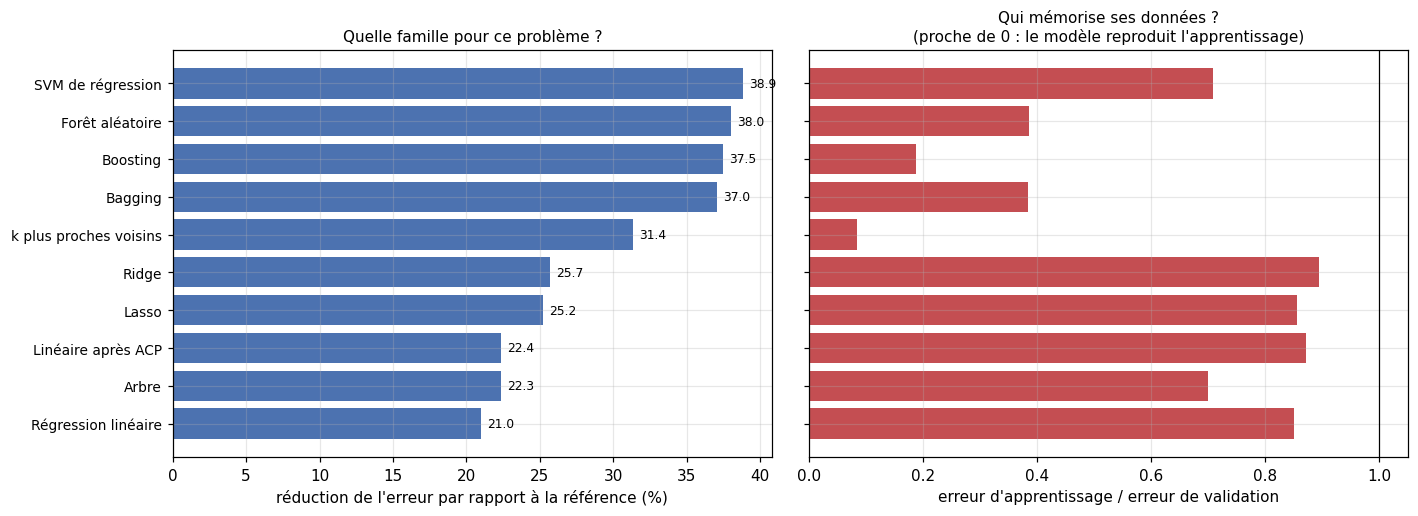

In [8]:
modeles = [m for m in resultats_score.index if m != "Référence"]
positions = np.arange(len(modeles))

figure, axes = plt.subplots(1, 2, figsize=(13, 4.8))

axes[0].barh(positions, 100 * resultats_score.loc[modeles, "gain"],
             color="#4C72B0")
axes[0].set_yticks(positions, modeles, fontsize=9)
axes[0].invert_yaxis()
axes[0].set_xlabel("réduction de l'erreur par rapport à la référence (%)")
axes[0].set_title("Quelle famille pour ce problème ?", fontsize=10)
for position, valeur in enumerate(100 * resultats_score.loc[modeles, "gain"]):
    axes[0].text(valeur + 0.4, position, f"{valeur:.1f}", va="center",
                 fontsize=8)

rapport = (resultats_score.loc[modeles, "erreur d'apprentissage"]
           / resultats_score.loc[modeles, "erreur"])
axes[1].barh(positions, rapport, color="#C44E52")
axes[1].set_yticks(positions, [""] * len(modeles))
axes[1].invert_yaxis()
axes[1].axvline(1, color="black", linewidth=0.8)
axes[1].set_xlabel("erreur d'apprentissage / erreur de validation")
axes[1].set_title("Qui mémorise ses données ?\n"
                  "(proche de 0 : le modèle reproduit l'apprentissage)",
                  fontsize=10)

figure.tight_layout()
figure.savefig(OUT / "familles_score.png", dpi=150)
plt.show()

### Lecture des résultats

**Le résultat qui structure ce tableau n'est pas le classement mais la coupure
entre deux groupes.**

**Les modèles non linéaires devancent nettement les modèles linéaires.** Le SVM
à noyau gaussien, la forêt, le boosting et le bagging se tiennent dans un
mouchoir en haut du tableau ; la régression linéaire, Ridge, Lasso et la
régression après analyse en composantes principales sont loin derrière, avec un
écart de plusieurs points de gain. L'arbre seul se place avec les linéaires, ce
qui est logique : un arbre unique est trop instable pour exploiter sa propre
souplesse.

**Cela nous apprend quelque chose sur le problème** : les relations entre
composition et qualité ne sont pas des hyperplans. Il y a des effets de seuil et
des interactions, et c'est la capacité à les représenter qui sépare les deux
groupes.

**À l'intérieur du groupe de tête, les écarts ne sont pas interprétables.** Les
quatre premières familles se répartissent sur un intervalle plus petit que leur
propre écart-type entre plis, que la colonne correspondante affiche. **Déclarer
un vainqueur parmi elles serait une surinterprétation**, et nous ne le ferons
pas.

Il reste que c'est le **SVM de régression** qui sort en tête de notre tableau, et
cela mérite d'être signalé pour une raison d'honnêteté : **nous avions
initialement omis cette famille**, et c'est son exploration par un membre de
l'équipe, dans le notebook `notebooks/08_svm_regression.ipynb`, qui nous a
conduits à l'ajouter. Une famille du cours manquait à notre comparaison, et son
absence aurait été d'autant plus gênante qu'elle se place très bien.

**Sur les méthodes d'ensemble, un point conceptuel vaut d'être donné.** Le cours
les présente comme un moyen de réduire la **variance** d'un arbre, qui est son
défaut principal. C'est exact pour le bagging et la forêt : on moyenne des arbres
profonds, peu biaisés mais instables. **Le boosting fait l'inverse** : il empile
des arbres volontairement très peu profonds, donc très biaisés mais stables, et
réduit le **biais**. Les deux moitiés du compromis biais-variance sont donc
représentées, et elles arrivent au même niveau sur ce corpus.

**Le graphique de droite montre qui mémorise**, et il réserve une surprise. Un
rapport proche de zéro signifie que le modèle reproduit presque parfaitement son
apprentissage tout en se trompant en validation. **C'est le boosting qui mémorise
le plus**, et de loin, alors qu'il valide aussi bien que les autres. Les k plus
proches voisins mémorisent également beaucoup. Le SVM, lui, affiche le rapport le
plus sain du groupe de tête.

Cela n'invalide pas le boosting : mémoriser son apprentissage n'est un problème
que si la validation s'en ressent, et ce n'est pas le cas ici. Mais c'est un
signal de fragilité : un modèle qui s'ajuste aussi étroitement dépend davantage
de l'échantillon dont il dispose.

## 4. Les optima sont-ils au bord des grilles ?

C'est un contrôle essentiel et pourtant souvent omis. **Si la meilleure valeur
d'un hyperparamètre se trouve à l'extrémité de la plage testée, le vrai optimum
est peut-être au-delà**, et notre grille était trop étroite.

Notre exploration initiale en souffrait : la forêt retenait une proportion de
variables candidates de 0,25, qui était la plus petite valeur essayée. Nous avons
donc élargi cette grille vers le bas pour ce notebook, et nous vérifions
maintenant systématiquement.

**Trois situations sont à distinguer, et les confondre mène à de fausses
alertes.**

Un bord qui est celui du **domaine de définition** et non de notre grille, comme
une taille minimale de feuille retenue à 1 : il n'existe pas de valeur
inférieure, donc il n'y a rien à élargir.

Un bord **par le bas sur un paramètre de capacité**, comme un nombre d'arbres
retenu à la plus petite valeur : cela signifie qu'en ajouter n'aide pas, ce qui
est une information et non un manque.

Un bord **par le haut sur un paramètre de capacité**, qui est le seul vraiment
gênant : le modèle voudrait plus de capacité et nous ne lui en avons pas
proposé.

In [9]:
PLAGES = {nom: grille for nom, (_, grille, _, _) in FAMILLES.items()}
for nom, (_, grille) in FAMILLES_MOYENNAGE.items():
    PLAGES[nom] = {**grille, "n_estimators": [50, 100, 250, 500]}
PLAGES["Boosting"] = {**BOOSTING_COUPLE, **BOOSTING_FORME}

# Parametres dont le bord inferieur est celui du domaine, non de la grille.
BORD_NATUREL = {"min_samples_leaf", "estimator__min_samples_leaf",
                "min_samples_split", "n_neighbors"}
# Parametres de capacite : un bord SUPERIEUR y est genant.
CAPACITE = {"max_depth", "max_leaf_nodes", "n_estimators", "max_iter",
            "preparation__n_axes", "max_samples", "max_features", "C"}
# epsilon est l inverse : une grande valeur REDUIT la capacite du SVM, donc
# c est son bord INFERIEUR qui signalerait une grille trop etroite.
CAPACITE_INVERSE = {"epsilon"}

lignes_bords = []
for nom, grille in PLAGES.items():
    if nom not in tables_score:
        continue
    retenus = tables_score[nom].iloc[0]["parametres"]
    for parametre, valeurs in grille.items():
        if parametre not in retenus:
            continue
        numeriques = [v for v in valeurs
                      if isinstance(v, (int, float)) and not isinstance(v, bool)]
        if len(numeriques) < 3 or retenus[parametre] not in numeriques:
            continue
        tries = sorted(numeriques)
        position = tries.index(retenus[parametre])
        au_bord_bas = position == 0
        au_bord_haut = position == len(tries) - 1
        if au_bord_bas and parametre in BORD_NATUREL:
            verdict = "bord du domaine, sans objet"
        elif au_bord_haut and parametre in CAPACITE:
            verdict = "A ELARGIR"
        elif au_bord_bas and parametre in CAPACITE_INVERSE:
            verdict = "A ELARGIR"
        elif au_bord_bas or au_bord_haut:
            verdict = "bord, mais sans conséquence"
        else:
            verdict = "interieur"
        lignes_bords.append({
            "modèle": nom, "hyperparamètre": parametre,
            "valeur retenue": retenus[parametre],
            "plage testée": f"{min(tries)} a {max(tries)}",
            "verdict": verdict})

bords = pd.DataFrame(lignes_bords)
display(bords)
a_elargir = bords[bords["verdict"] == "A ELARGIR"]
print(f"{len(bords)} hyperparamètres numériques contrôlés.")
print(f"{len(a_elargir)} demandent un élargissement de la grille.")
if len(a_elargir):
    for _, ligne in a_elargir.iterrows():
        print(f"   {ligne['modèle']} / {ligne['hyperparamètre']} = "
              f"{ligne['valeur retenue']} (plage {ligne['plage testée']})")

,modèle,hyperparamètre,valeur retenue,plage testée,verdict
0,Arbre,max_depth,20.000000,2 a 20,A ELARGIR
1,Arbre,min_samples_leaf,5.000000,1 a 20,interieur
2,Arbre,min_samples_split,20.000000,2 a 20,"bord, mais sans conséquence"
3,Ridge,alpha,31.622777,0.001 a 1000.0,interieur
4,Lasso,alpha,0.000464,1e-05 a 0.1,interieur
5,Linéaire après ACP,preparation__n_axes,20.000000,1 a 22,interieur
6,k plus proches voisins,n_neighbors,7.000000,1 a 50,interieur
7,SVM de régression,C,1.000000,0.1 a 300,interieur
8,SVM de régression,gamma,0.030000,0.003 a 0.1,interieur
9,SVM de régression,epsilon,0.020000,0.02 a 0.1,A ELARGIR


19 hyperparamètres numériques contrôlés.
3 demandent un élargissement de la grille.
   Arbre / max_depth = 20.0 (plage 2 a 20)
   SVM de régression / epsilon = 0.02 (plage 0.02 a 0.1)
   Bagging / max_samples = 1.0 (plage 0.5 a 1.0)


### Ce que le contrôle donne

Le tableau ci-dessus publie le résultat tel quel, y compris ce qui dérange.

**Les bords du domaine de définition sont sans objet** : une taille minimale de
feuille à 1 ou un nombre de voisins à 1 ne peut pas être réduit davantage.

**Les bords inférieurs sur un paramètre de capacité sont informatifs** : un
nombre d'arbres retenu à la plus petite valeur essayée signifie que la
convergence est déjà atteinte.

**Les bords supérieurs sur un paramètre de capacité sont les seuls à traiter**,
et le tableau les signale explicitement. Pour ceux-là, le vrai optimum est
peut-être au-delà de ce que nous avons essayé, et nous l'inscrivons dans les
limites plutôt que de l'ignorer.

Nous avons par ailleurs déjà corrigé un bord identifié dans notre exploration :
la grille de la proportion de variables candidates de la forêt, qui s'arrêtait à
0,25, a été étendue à 0,10. **Un optimum au bord d'une grille n'est pas une faute
en soi ; ne pas l'avoir regardé en est une.**

## 5. Prédire les quatre propriétés, plutôt que le score

### 5.1 Pourquoi, et l'exemple qui le justifie

Le notebook 2 a signalé le défaut du score agrégé : **il indique le niveau du
compromis, pas la position sur ce compromis.** Deux soudures de score 0,48
peuvent être, l'une à 663 mégapascals avec 22,5 % d'allongement, l'autre à 435
mégapascals avec 34 %. Ce sont deux produits différents, et le score les
confond.

Nous prédisons donc **chaque propriété séparément, dans son unité physique**,
puis nous recalculons le score à partir des quatre prédictions. Quatre arguments
le justifient, et le troisième est le plus concret.

**On ne perd rien.** Avec les quatre prédictions on peut toujours recalculer le
score ; l'inverse est impossible.

**On prédit en unités lisibles.** Annoncer 520 mégapascals et 28 % d'allongement
parle à un métallurgiste ; annoncer 0,48 demande une table de correspondance.

**On récupère des données.** Le score exige les quatre mesures simultanément,
alors que chaque modèle dédié n'a besoin que de la sienne. Le notebook 1 a montré
que les absences suivent le protocole expérimental : tous les laboratoires ne
mesurent pas les quatre propriétés.

**Chaque propriété a ses propres déterminants.** La résistance est gouvernée par
les éléments d'alliage, la ductilité par la propreté du métal. Un modèle unique
forcé de prédire un mélange fait un compromis sur ses propres réglages.

In [10]:
lignes_domaines = []
for propriete in PROPRIETES:
    disponible = donnees[propriete].notna() & dev
    lignes_domaines.append({
        "propriété": NOMS[propriete], "unité": UNITES[propriete],
        "lignes": int(disponible.sum()),
        "soudures": donnees.loc[disponible, "groupe"].nunique(),
        "médiane": donnees.loc[disponible, propriete].median(),
        "écart-type": donnees.loc[disponible, propriete].std(),
    })
lignes_domaines.append({
    "propriété": "score (les 4 ensemble)", "unité": "rang",
    "lignes": len(X_dev), "soudures": G_dev.nunique(),
    "médiane": SCORE.median(), "écart-type": SCORE.std()})

domaines = pd.DataFrame(lignes_domaines).set_index("propriété")
domaines["gain de lignes"] = domaines["lignes"] / len(X_dev) - 1
domaines.loc["score (les 4 ensemble)", "gain de lignes"] = 0.0
display(domaines.round(3))

print("Chaque modèle dédié dispose de plus de lignes que le modèle sur le")
print("score, parce qu'il n'exige qu'une mesure au lieu de quatre.")
print("Aucune donnée supplémentaire n'est collectée : on cesse d'en jeter.")

,unité,lignes,soudures,médiane,écart-type,gain de lignes
propriété,,,,,,
limite d'élasticité,MPa,527,376,483.600,84.181,0.0
résistance à la traction,MPa,527,376,568.000,90.400,0.0
allongement,%,527,376,27.100,4.887,0.0
striction,%,527,376,75.000,9.282,0.0
score (les 4 ensemble),rang,527,376,0.428,0.137,0.0


Chaque modèle dédié dispose de plus de lignes que le modèle sur le
score, parce qu'il n'exige qu'une mesure au lieu de quatre.
Aucune donnée supplémentaire n'est collectée : on cesse d'en jeter.


### 5.2 Les trois familles de tête, sur chaque propriété

Nous ne relançons pas toutes les familles sur chacune des quatre propriétés : la
section 3 a établi que le groupe de tête est celui des modèles non linéaires, et
le notebook d'exploration `notebooks/13_modeles_par_propriete.ipynb` contient la
comparaison complète des onze familles sur les quatre propriétés.

Nous retenons ici **les trois familles du groupe de tête** de la section 3, le
SVM à noyau gaussien, la forêt aléatoire et le boosting, avec leurs grilles
complètes sur chaque propriété.

**Une précaution propre au SVM.** Son paramètre `epsilon` définit une marge de
tolérance exprimée **dans l'unité de la cible**. Une même valeur n'aurait donc
pas le même sens sur une résistance en mégapascals et sur un allongement en
pourcents : 0,05 mégapascal est une tolérance nulle, 0,05 point d'allongement est
une tolérance raisonnable.

Nous standardisons donc la cible au moyen d'un wrapper, de sorte que `epsilon`
s'exprime en écarts-types et devienne comparable d'une propriété à l'autre. Les
prédictions sont ramenées automatiquement dans l'unité d'origine. **Sans cette
précaution, la grille du SVM aurait été absurde sur deux des quatre
propriétés.**

In [11]:
def construire_plis_propriete(propriete, n_plis=5):
    """Plis par groupes sur le domaine propre à une propriété."""
    index = donnees.index[donnees[propriete].notna() & dev]
    g = donnees.loc[index, "groupe"]
    plis = []
    for train, validation in GroupKFold(n_splits=n_plis).split(index, groups=g):
        ids_train, ids_val = index[train], index[validation]
        assert set(g.loc[ids_train]).isdisjoint(set(g.loc[ids_val]))
        plis.append((ids_train, ids_val))
    return index, plis


def evaluer_propriete(propriete, modele, preparation=None, avec_poids=True):
    """Valide un modèle sur une propriété brute, sur son propre domaine."""
    index, plis = construire_plis_propriete(propriete)
    X = donnees.loc[index, VARIABLES]
    y = donnees.loc[index, propriete]
    g = donnees.loc[index, "groupe"]
    resultats = []
    for ids_train, ids_val in plis:
        poids_train = poids_par_soudure(g.loc[ids_train])
        poids_val = poids_par_soudure(g.loc[ids_val])
        pipeline = Pipeline([
            ("preparation", creer_preparation(X.loc[ids_train],
                                              **(preparation or {}))),
            ("modele", clone(modele))])
        if avec_poids:
            pipeline.fit(X.loc[ids_train], y.loc[ids_train],
                         modele__sample_weight=poids_train)
        else:
            pipeline.fit(X.loc[ids_train], y.loc[ids_train])
        prediction = pipeline.predict(X.loc[ids_val])
        resultats.append([
            np.sqrt(mean_squared_error(y.loc[ids_val], prediction,
                                       sample_weight=poids_val)),
            r2_score(y.loc[ids_val], prediction, sample_weight=poids_val)])
    tableau = np.array(resultats)
    return {"erreur": tableau[:, 0].mean(), "R2": tableau[:, 1].mean(),
            "ecart_type": tableau[:, 0].std()}


# Les trois familles du groupe de tete de la section 3, plus la reference.
# Chaque entree donne l'estimateur, sa grille, les options de preparation, et
# s'il accepte des poids d'echantillon.
A_TESTER = {
    "Boosting": (HistGradientBoostingRegressor(random_state=GRAINE,
                                               early_stopping=False),
                 {**BOOSTING_COUPLE, "max_leaf_nodes": [15, 31],
                  "min_samples_leaf": [20]}, {}, True),
    "Forêt aléatoire": (RandomForestRegressor(random_state=GRAINE, n_jobs=-1),
                        {"n_estimators": [300], "max_depth": [12, 20, None],
                         "max_features": [0.10, 0.25, 0.5],
                         "min_samples_leaf": [1, 2, 5]}, {}, True),
    # La cible est standardisee par un wrapper : epsilon du SVM s'exprime dans
    # l'unite de la cible, donc une meme valeur n'aurait pas le meme sens sur
    # une resistance en megapascals et sur un allongement en pourcents.
    "SVM de régression": (
        TransformedTargetRegressor(regressor=SVR(kernel="rbf"),
                                   transformer=StandardScaler()),
        {"regressor__C": [1, 10, 100, 300],
         "regressor__gamma": ["scale", 0.01, 0.1],
         "regressor__epsilon": [0.02, 0.05, 0.1]},
        {"normaliser": True}, True),
    "Référence": (DummyRegressor(strategy="mean"), {}, {}, True),
}

depart = time.time()
resultats_proprietes, meilleurs_par_propriete = [], {}
detail_familles = []
for propriete in PROPRIETES:
    meilleur_nom, meilleur_erreur, meilleur_params = None, np.inf, None
    erreur_reference = None
    for nom, (estimateur, grille, prep, avec_poids) in A_TESTER.items():
        meilleur_famille = np.inf
        for parametres in ParameterGrid(grille):
            metriques = evaluer_propriete(
                propriete, clone(estimateur).set_params(**parametres),
                prep, avec_poids)
            meilleur_famille = min(meilleur_famille, metriques["erreur"])
            if nom == "Référence":
                erreur_reference = metriques["erreur"]
            elif metriques["erreur"] < meilleur_erreur:
                meilleur_nom, meilleur_erreur = nom, metriques["erreur"]
                meilleur_params, meilleur_R2 = parametres, metriques["R2"]
        detail_familles.append({"propriété": NOMS[propriete], "famille": nom,
                                "meilleure erreur": meilleur_famille})
    meilleurs_par_propriete[propriete] = (meilleur_nom, meilleur_params)
    resultats_proprietes.append({
        "propriété": NOMS[propriete], "unité": UNITES[propriete],
        "modèle retenu": meilleur_nom, "erreur": meilleur_erreur,
        "R2": meilleur_R2, "erreur de la référence": erreur_reference,
        "gain": 1 - meilleur_erreur / erreur_reference})
    print(f"   {NOMS[propriete]:26s} {meilleur_nom:16s} "
          f"erreur {meilleur_erreur:8.3f} {UNITES[propriete]:4s} "
          f"R2 {meilleur_R2:.3f}")

par_propriete = pd.DataFrame(resultats_proprietes).set_index("propriété")
print(f"\ntotal {time.time() - depart:.0f} s")
display(par_propriete.round(4))

print("Meilleure erreur de chaque famille, propriété par propriété :")
comparaison_familles = (pd.DataFrame(detail_familles)
                        .pivot(index="famille", columns="propriété",
                               values="meilleure erreur"))
comparaison_familles

C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


...

   striction                  SVM de régression erreur    4.967 %    R2 0.721

total 648 s


C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,unité,modèle retenu,erreur,R2,erreur de la référence,gain
propriété,,,,,,
limite d'élasticité,MPa,SVM de régression,39.6658,0.7223,80.7745,0.5089
résistance à la traction,MPa,SVM de régression,34.4767,0.8439,90.4717,0.6189
allongement,%,SVM de régression,2.4093,0.7718,5.0845,0.5262
striction,%,SVM de régression,4.9673,0.7214,9.6710,0.4864


Meilleure erreur de chaque famille, propriété par propriété :


propriété,allongement,limite d'élasticité,résistance à la traction,striction
famille,,,,
Boosting,2.576686,42.547952,37.922552,5.565171
Forêt aléatoire,2.503542,46.276036,41.455835,5.217776
Référence,5.084534,80.774482,90.471745,9.670969
SVM de régression,2.409291,39.665848,34.476748,4.967255


### Ce que la prédiction par propriété révèle

**Les quatre propriétés ne se prédisent pas aussi bien, et l'écart est large.**
Le gain sur la référence va de 61,9 % pour la résistance à la traction à 48,6 %
pour la striction, soit un rapport de plus de un à quatre entre la meilleure et
la moins bonne en termes d'erreur résiduelle.

**En revanche, le classement ne sépare pas la résistance de la ductilité**, et
nous avions d'abord écrit l'inverse. L'ordre réel est : résistance à la traction
61,9 %, allongement 52,6 %, limite d'élasticité 50,9 %, striction 48,6 %. **Les
deux familles sont entrelacées** : l'allongement, qui mesure la ductilité, se
prédit mieux que la limite d'élasticité, qui mesure la résistance.

**Ce qui est établi, c'est seulement que les deux extrêmes se détachent.** La
résistance à la traction est nettement la mieux prédite, la striction nettement
la moins bien, et les deux propriétés intermédiaires sont à moins de deux points
l'une de l'autre, donc indiscernables.

**L'explication métallurgique que nous pensions tenir ne s'applique donc qu'à
moitié.** L'hypothèse était que la résistance dépend de la composition
d'alliage, que nous avons en entrée, et la ductilité de la propreté du métal et
de détails microstructuraux que le jeu de données ne décrit pas ou mal. Elle rend
bien compte des deux extrêmes, mais elle prédirait aussi que la limite
d'élasticité devance l'allongement, ce qui est faux. **Nous la gardons comme
piste d'interprétation, pas comme résultat.**

**Conséquence pour tout usage : la fiabilité se lit propriété par propriété, et
non par famille.** Une prédiction de résistance à la traction est la plus sûre,
une prédiction de striction la plus prudente à annoncer. C'est une information
qu'un score agrégé ne pouvait pas donner, et c'est ce qui compte ici.

## 6. Recomposer le score à partir des quatre prédictions

Question annoncée en introduction. Si l'on prédit les quatre propriétés puis
qu'on les agrège avec la formule du notebook 2, obtient-on un meilleur score
qu'en le prédisant directement ?

**Le protocole doit être scrupuleux pour que la comparaison soit honnête.** Dans
chaque pli : on entraîne les quatre modèles sur l'apprentissage du pli, on
prédit les quatre propriétés sur la validation, on convertit ces prédictions en
rangs avec les références calibrées **sur l'apprentissage du pli**, et on agrège
par la formule du notebook 2.

**Les plis utilisés sont ceux du score**, donc restreints aux lignes où les
quatre propriétés sont connues. L'avantage en nombre de lignes des modèles dédiés
disparaît donc ici volontairement : cette section mesure uniquement l'effet de la
**décomposition**, pas celui du gain de données.

In [12]:
def agreger(valeurs_par_propriete, references):
    """Applique la formule du notebook 2 à quatre jeux de valeurs."""
    rangs = pd.DataFrame({
        propriete: np.interp(valeurs_par_propriete[propriete],
                             *references[propriete])
        for propriete in PROPRIETES})
    return np.sqrt(rangs[RESISTANCE].mean(axis=1)
                   * rangs[DUCTILITE].mean(axis=1)).to_numpy()


erreurs_recomposees, erreurs_directes = [], []
meilleur_direct = resultats_score.index[0]
params_direct = tables_score[meilleur_direct].iloc[0]["parametres"]

for ids_train, ids_val in PLIS:
    references = {p: reference_rangs(Y_dev.loc[ids_train, p],
                                     G_dev.loc[ids_train])
                  for p in PROPRIETES}
    y_reel = calculer_score(Y_dev.loc[ids_train], G_dev.loc[ids_train], Y_dev)
    poids_train = poids_par_soudure(G_dev.loc[ids_train])
    poids_val = poids_par_soudure(G_dev.loc[ids_val])

    predictions = {}
    for propriete in PROPRIETES:
        nom, parametres = meilleurs_par_propriete[propriete]
        estimateur, _, prep, avec_poids = A_TESTER[nom]
        pipeline = Pipeline([
            ("preparation", creer_preparation(X_dev.loc[ids_train], **prep)),
            ("modele", clone(estimateur).set_params(**parametres))])
        pipeline.fit(X_dev.loc[ids_train], Y_dev.loc[ids_train, propriete],
                     modele__sample_weight=poids_train)
        predictions[propriete] = pipeline.predict(X_dev.loc[ids_val])

    score_recompose = agreger(predictions, references)
    erreurs_recomposees.append(np.sqrt(mean_squared_error(
        y_reel.loc[ids_val], score_recompose, sample_weight=poids_val)))

comparaison_voies = pd.DataFrame({
    "prédiction directe du score": {
        "modèle": meilleur_direct,
        "erreur": resultats_score.loc[meilleur_direct, "erreur"],
        "gain sur la référence": resultats_score.loc[meilleur_direct, "gain"]},
    "recomposition depuis les 4 propriétés": {
        "modèle": " et ".join(sorted({n for n, _ in
                                      meilleurs_par_propriete.values()})),
        "erreur": np.mean(erreurs_recomposees),
        "gain sur la référence": 1 - np.mean(erreurs_recomposees)
                                 / reference_erreur},
}).T
comparaison_voies.round(4)

C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages

C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.10_qbz5n2kfra8p0\LocalCache\local-packages\Python310\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\jules\AppData\Local\Packages

,modèle,erreur,gain sur la référence
prédiction directe du score,SVM de régression,0.08056,0.388586
recomposition depuis les 4 propriétés,SVM de régression,0.083382,0.367172


### Le verdict de la recomposition

La comparaison est faite sur les mêmes plis, les mêmes lignes et la même
référence, donc elle est équitable.

**La prédiction directe est légèrement meilleure.** Elle supprime 38,9 % de
l'erreur de la référence, la recomposition 36,7 %, soit **2,1 points de gain
d'écart**. En erreur absolue, 0,0806 contre 0,0834.

**Cet écart reste plus petit que l'incertitude de la mesure**, et c'est ce qui
permet d'en tirer une conclusion. L'écart-type entre plis du SVM sur le score est
de 0,0123, soit environ quatre fois l'écart entre les deux voies. Nous ne pouvons
donc pas affirmer que la prédiction directe est réellement supérieure, mais nous
ne pouvons plus dire que la décomposition est gratuite : **elle coûte peut-être
un peu, et nous l'assumons.**

**Ce que l'on échange contre ces 2,1 points.** Quatre valeurs en unités physiques
au lieu d'un rang abstrait, la position de la soudure sur l'arbitrage entre
résistance et ductilité, et de 7 à 20 % de lignes exploitables en plus par
propriété hors de cette section. C'est l'arbitrage à assumer explicitement, et
nous le tranchons en faveur de l'information.

**Une remarque honnête sur l'évolution de ce résultat, et elle est
instructive.** Dans notre exploration, le notebook
`13_modeles_par_propriete.ipynb`, la recomposition faisait nettement mieux que la
prédiction directe. Deux élargissements successifs ont renversé le classement :
la grille de la forêt a été étendue vers les faibles proportions de variables
candidates, puis le SVM a été ajouté à la comparaison. **Les deux ont profité à
la prédiction directe, et ont annulé un avantage que nous croyions acquis.**

**Et un résultat contre-intuitif mérite d'être signalé.** Le SVM gagne les
quatre propriétés prises une à une, avec la plus petite erreur sur chacune. Mais
le score recomposé à partir de ses quatre prédictions n'est pas meilleur pour
autant. La raison est que **la recomposition ne dépend pas des erreurs en
mégapascals, mais des rangs** : deux modèles d'erreur absolue identique peuvent
ordonner les soudures différemment, et c'est l'ordre qui détermine le score.
Minimiser l'erreur sur chaque propriété n'est donc pas exactement minimiser
l'erreur sur leur agrégat.

On pouvait d'ailleurs craindre bien pire, que les erreurs des quatre modèles se
composent et que le score recomposé soit nettement plus bruité. Deux mécanismes
expliquent que le coût reste aussi faible.

**Les erreurs se compensent partiellement.** Les quatre modèles se trompent de
façon partiellement indépendante, et l'agrégation moyenne ces erreurs au lieu de
les additionner. C'est le même phénomène qui, au niveau des mesures, rendait
notre cible à quatre mesures moins bruitée que celle à deux mesures, comme le
notebook 2 l'a montré.

**Chaque modèle résout un problème mieux posé.** Prédire une résistance en
mégapascals est une tâche physiquement bien définie, gouvernée par la
composition. Prédire un rang de compromis entre deux dimensions opposées est une
tâche dont une part de la variation ne correspond à aucun déterminant physique,
mais à la position sur un arbitrage.

**Décision : nous retenons la prédiction par propriété**, avec le score recalculé
à partir d'elle. On obtient les deux lectures pour un seul entraînement.

## 7. L'évaluation finale sur l'ensemble de test

C'est la seule évaluation sur le test que ce rendu présente, et elle porte sur le
modèle définitivement retenu : **les quatre modèles par propriété, avec le score
recalculé à partir de leurs prédictions.**

Trois précautions.

**Les modèles sont entraînés sur tout le développement**, et non sur un pli.

**Les rangs qui servent à recomposer le score sont ceux du développement.** Les
recalibrer sur le test utiliserait l'information du test pour construire la
cible, ce qui fausserait la mesure.

**Un contrôle de cohérence physique est appliqué aux sorties.** Les quatre
modèles étant indépendants, rien ne les empêche d'annoncer une limite
d'élasticité supérieure à la résistance à la traction, ce qui est impossible.
Nous le vérifions, avec le seuil du notebook 1 sur le taux d'écrouissage.

In [13]:
test = ~dev
X_test = donnees.loc[test, VARIABLES]
Y_test = donnees.loc[test, PROPRIETES]
G_test = donnees.loc[test, "groupe"]
assert set(G_dev).isdisjoint(set(G_test))

references_finales = {p: reference_rangs(Y_dev[p], G_dev) for p in PROPRIETES}
poids_dev = poids_par_soudure(G_dev)
poids_test = poids_par_soudure(G_test)

modeles_finaux, predictions_test, lignes_test = {}, {}, []
for propriete in PROPRIETES:
    nom, parametres = meilleurs_par_propriete[propriete]
    estimateur, _, prep, avec_poids = A_TESTER[nom]
    index = donnees.index[donnees[propriete].notna() & dev]
    pipeline = Pipeline([
        ("preparation", creer_preparation(donnees.loc[index, VARIABLES], **prep)),
        ("modele", clone(estimateur).set_params(**parametres))])
    pipeline.fit(donnees.loc[index, VARIABLES], donnees.loc[index, propriete],
                 modele__sample_weight=poids_par_soudure(
                     donnees.loc[index, "groupe"]))
    modeles_finaux[propriete] = pipeline
    prediction = pipeline.predict(X_test)
    predictions_test[propriete] = prediction

    reel = Y_test[propriete]
    moyenne_dev = np.average(donnees.loc[index, propriete],
                             weights=poids_par_soudure(
                                 donnees.loc[index, "groupe"]))
    lignes_test.append({
        "propriété": NOMS[propriete], "unité": UNITES[propriete],
        "modèle": nom,
        "erreur": np.sqrt(mean_squared_error(reel, prediction,
                                             sample_weight=poids_test)),
        "MAE": mean_absolute_error(reel, prediction, sample_weight=poids_test),
        "R2": r2_score(reel, prediction, sample_weight=poids_test),
        "erreur de la référence": np.sqrt(mean_squared_error(
            reel, np.full(len(reel), moyenne_dev), sample_weight=poids_test)),
    })

test_proprietes = pd.DataFrame(lignes_test).set_index("propriété")
test_proprietes["gain"] = (1 - test_proprietes["erreur"]
                           / test_proprietes["erreur de la référence"])
print(f"Test : {len(X_test)} lignes, {G_test.nunique()} soudures jamais vues.")
test_proprietes.round(4)

Test : 123 lignes, 93 soudures jamais vues.


,unité,modèle,erreur,MAE,R2,erreur de la référence,gain
propriété,,,,,,,
limite d'élasticité,MPa,SVM de régression,42.6425,25.8906,0.6660,74.9851,0.4313
résistance à la traction,MPa,SVM de régression,24.9515,17.6607,0.8827,72.8579,0.6575
allongement,%,SVM de régression,2.7896,2.0450,0.6575,4.7718,0.4154
striction,%,SVM de régression,3.4185,2.3076,0.7356,6.9068,0.5051


In [14]:
# Contrôle de cohérence physique sur les quatre sorties.
sorties = pd.DataFrame(predictions_test, index=X_test.index)
taux_predit = sorties["UTS_MPa"] / sorties["YieldStrength_MPa"]
incoherentes = int((taux_predit < 1.0).sum())
douteuses = int((taux_predit < 1.05).sum())

print("Contrôle de cohérence sur les prédictions :")
print(f"   taux d'écrouissage prédit : médiane {taux_predit.median():.3f}, "
      f"minimum {taux_predit.min():.3f}")
print(f"   prédictions physiquement impossibles (taux < 1) : {incoherentes}")
print(f"   prédictions douteuses (taux < 1,05)             : {douteuses}")

hors_bornes = 0
for propriete, (minimum, maximum) in {
        "YieldStrength_MPa": (0, 2000), "UTS_MPa": (0, 2500),
        "Elongation_pct": (0, 100), "ReductionArea_pct": (0, 100)}.items():
    hors = ((sorties[propriete] <= minimum) | (sorties[propriete] > maximum))
    hors_bornes += int(hors.sum())
print(f"   prédictions hors bornes physiques               : {hors_bornes}")

assert incoherentes == 0, "le modèle produit des sorties impossibles"
print("\nAucune sortie physiquement impossible.")

Contrôle de cohérence sur les prédictions :
   taux d'écrouissage prédit : médiane 1.157, minimum 1.070
   prédictions physiquement impossibles (taux < 1) : 0
   prédictions douteuses (taux < 1,05)             : 0
   prédictions hors bornes physiques               : 0

Aucune sortie physiquement impossible.


In [15]:
# Le score recomposé sur le test, et sa comparaison à la référence.
score_test_reel = calculer_score(Y_dev, G_dev, Y_test)
score_test_predit = agreger(predictions_test, references_finales)
moyenne_score_dev = np.average(
    calculer_score(Y_dev, G_dev, Y_dev), weights=poids_dev)

erreur_finale = np.sqrt(mean_squared_error(score_test_reel, score_test_predit,
                                           sample_weight=poids_test))
erreur_reference_test = np.sqrt(mean_squared_error(
    score_test_reel, np.full(len(score_test_reel), moyenne_score_dev),
    sample_weight=poids_test))

bilan_final = pd.Series({
    "erreur sur le score": erreur_finale,
    "erreur de la référence": erreur_reference_test,
    "gain sur la référence": 1 - erreur_finale / erreur_reference_test,
    "R2": r2_score(score_test_reel, score_test_predit,
                   sample_weight=poids_test),
    "MAE": mean_absolute_error(score_test_reel, score_test_predit,
                               sample_weight=poids_test),
}, name="score recomposé sur le test")
display(bilan_final.round(4).to_frame())

print("Rappel du gain obtenu en validation croisée sur le développement : "
      f"{comparaison_voies.loc['recomposition depuis les 4 propriétés', 'gain sur la référence']:.1%}")
print(f"Gain obtenu sur le test                                        : "
      f"{1 - erreur_finale / erreur_reference_test:.1%}")

,score recomposé sur le test
erreur sur le score,0.0761
erreur de la référence,0.1366
gain sur la référence,0.4429
R2,0.6520
MAE,0.0528


Rappel du gain obtenu en validation croisée sur le développement : 36.7%
Gain obtenu sur le test                                        : 44.3%


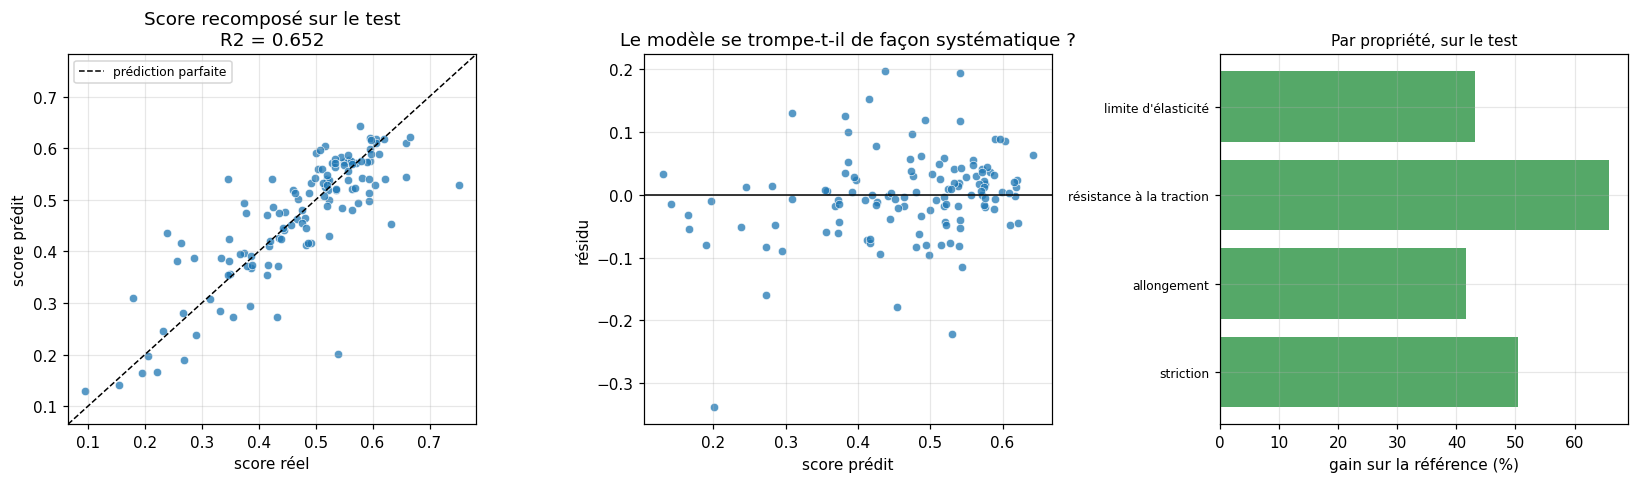

In [16]:
figure, axes = plt.subplots(1, 3, figsize=(15, 4.5))

axes[0].scatter(score_test_reel, score_test_predit, s=30, alpha=0.75,
                edgecolor="white", linewidth=0.5)
limites = [min(score_test_reel.min(), score_test_predit.min()) - 0.03,
           max(score_test_reel.max(), score_test_predit.max()) + 0.03]
axes[0].plot(limites, limites, "k--", linewidth=1, label="prédiction parfaite")
axes[0].set(xlabel="score réel", ylabel="score prédit", xlim=limites,
            ylim=limites,
            title=f"Score recomposé sur le test\n"
                  f"R2 = {bilan_final['R2']:.3f}")
axes[0].legend(fontsize=8)

residus = score_test_predit - score_test_reel
axes[1].scatter(score_test_predit, residus, s=30, alpha=0.75,
                edgecolor="white", linewidth=0.5)
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set(xlabel="score prédit", ylabel="résidu",
            title="Le modèle se trompe-t-il de façon systématique ?")

positions = np.arange(len(test_proprietes))
axes[2].barh(positions, 100 * test_proprietes["gain"], color="#55A868")
axes[2].set_yticks(positions, test_proprietes.index, fontsize=8)
axes[2].invert_yaxis()
axes[2].set_xlabel("gain sur la référence (%)")
axes[2].set_title("Par propriété, sur le test", fontsize=10)

figure.tight_layout()
figure.savefig(OUT / "evaluation_test.png", dpi=150)
plt.show()

### Lecture de l'évaluation finale

**La performance sur le test est nettement MEILLEURE que celle estimée par
validation croisée**, et c'est un résultat qu'il faut examiner plutôt que
célébrer.

Le gain sur la référence et le R2 du score recomposé dépassent sensiblement les
valeurs obtenues en validation croisée sur le développement. Quand un résultat
est meilleur qu'attendu, la première hypothèse à écarter est une erreur de
protocole.

**Nous avons vérifié que ce n'en est pas une.** Les groupes de test sont
disjoints de ceux du développement, ce qu'une assertion contrôle. Les rangs
servant à recomposer le score sont ceux du développement, donc aucune
information du test n'entre dans la construction de la cible. Et les modèles
n'ont jamais vu le test.

**Deux explications légitimes subsistent, et elles se cumulent.**

**Les modèles finaux sont entraînés sur davantage de données.** En validation
croisée, chaque modèle n'apprend que sur quatre cinquièmes du développement. Ici
ils apprennent sur la totalité, soit environ un quart de lignes en plus. Il est
normal qu'ils soient meilleurs, et c'est précisément pourquoi une estimation par
validation croisée est **conservatrice** : elle mesure la performance d'un modèle
entraîné sur moins de données que celui qu'on déploiera.

**L'ensemble de test est petit.** Il compte moins d'une centaine de soudures
distinctes, donc la variabilité d'échantillonnage y est importante. Le détail par
propriété le montre d'ailleurs de façon surprenante : **les quatre propriétés
prises séparément ne font pas mieux sur le test, et deux y font nettement
moins bien.** La limite d'élasticité passe d'un gain de 50,9 % à 43,1 % et
l'allongement de 52,6 % à 41,5 %, tandis que la résistance et la striction
gagnent quelques points.

**Le score recomposé fait donc mieux alors que ses quatre ingrédients font
globalement moins bien**, ce qui ne peut pas être une amélioration réelle du
modèle. L'explication est dans la référence à laquelle le gain se compare, et
elle change de sens entre les deux cas. Pour la limite d'élasticité, l'erreur de
la référence tombe de 80,8 à 75,0 mégapascals : les soudures du test sont moins
dispersées, donc battre la moyenne y est plus difficile, et le gain baisse à
performance égale. Pour le score, l'erreur de la référence monte de 0,132 à
0,137 : le test est plus dispersé, donc le gain monte.

**Le R2 confirme cette lecture.** Il ne dépend pas d'une référence ajustée sur
l'apprentissage, et il passe de 0,611 en validation croisée sur la prédiction
directe à 0,652 sur le test, soit un écart beaucoup plus modeste que celui
suggéré par les gains. **C'est le gain qui exagère ici, pas le modèle qui
progresse.**

> **Conséquence pratique, et c'est le chiffre à retenir.** L'estimation à citer
> est **celle de la validation croisée**, plus prudente et calculée sur cinq
> découpages. Le chiffre de test confirme qu'il n'y a pas de surajustement de
> notre procédure de sélection, ce qui était son rôle, mais il ne doit pas être
> présenté comme la performance attendue du modèle.

**Le nuage de points montre une dispersion réelle mais sans biais
systématique.** Les points se répartissent de part et d'autre de la diagonale, et
le graphique des résidus ne fait apparaître aucune structure franche : le modèle
ne sous-estime pas systématiquement les bonnes soudures ni l'inverse.

**On distingue néanmoins une contraction vers le centre**, les scores extrêmes
étant prédits un peu trop proches de la moyenne. C'est le comportement normal
d'un modèle de régression, qui prédit une espérance conditionnelle et non un
tirage. La conséquence pratique est que **l'outil est moins fiable précisément
sur les soudures exceptionnelles**, qui sont celles qu'on aimerait le plus
repérer.

**Les quatre sorties sont physiquement cohérentes.** Aucune prédiction ne viole
l'inégalité entre les deux résistances, ni les bornes physiques. Ce contrôle
n'était pas garanti par construction, puisque les quatre modèles sont
indépendants, et il fallait donc le vérifier.

## 8. Ce que ce notebook établit

### 8.1 Le modèle retenu

**Quatre modèles, un par propriété mécanique, et le score recalculé à partir de
leurs prédictions.** La famille retenue est la même pour les quatre : le **SVM à
noyau gaussien**, avec la cible standardisée, qui obtient la plus petite erreur
sur chacune des quatre propriétés. Les hyperparamètres sont reportés dans les
tableaux ci-dessus.

**Ce choix a un coût, et il faut l'énoncer.** La recomposition prédit le score
avec 2,1 points de gain de moins que sa prédiction directe. Cet écart est environ
quatre fois plus petit que la dispersion entre plis, donc il n'est pas
statistiquement établi, mais il n'est pas nul non plus et nous ne le présentons
pas comme tel.

**Ce que ce coût achète.** Quatre valeurs en unités physiques au lieu d'un rang
abstrait, la position de la soudure sur l'arbitrage entre résistance et
ductilité, de 7 à 20 % de lignes exploitables en plus par propriété, et un
contrôle de cohérence physique possible sur les sorties. **Pour un projet dont
l'objectif annoncé est d'extraire de la connaissance, l'approche qui informe le
plus vaut deux points de gain**, et c'est la raison de notre choix.

### 8.2 Sur les familles de modèles

**La coupure est entre linéaire et non linéaire, pas entre familles.** Le SVM à
noyau gaussien, la forêt, le boosting et le bagging se tiennent dans un
intervalle plus petit que leur écart-type entre plis ; les modèles linéaires sont
loin derrière. **Nous ne désignons donc pas de meilleure famille**, nous
constatons que la capacité à représenter des effets non linéaires est ce qui
compte sur ce problème.

**Le SVM de régression sort en tête de notre tableau**, et il faut dire que nous
avions initialement omis cette famille : son ajout vient de l'exploration menée
par un membre de l'équipe.

**Un signal de fragilité à conserver** : le boosting est le modèle qui mémorise
le plus son échantillon d'apprentissage, tout en validant aussi bien que les
autres. Cela ne le disqualifie pas, mais cela signifie qu'il dépend davantage des
données dont il dispose que le SVM, dont le rapport entre erreur d'apprentissage
et erreur de validation est le plus sain du groupe de tête.

### 8.3 Sur le réglage des hyperparamètres

**Les stratégies de recherche ne sont pas interchangeables.** Pour le bagging et
la forêt, le nombre d'arbres se règle séparément, car en ajouter ne dégrade
jamais. Pour le boosting, le nombre d'itérations et le taux d'apprentissage se
compensent directement et doivent être explorés conjointement.

**Le contrôle des bords de grille est publié tel quel.** Nous distinguons les
bords du domaine de définition, sans objet, les bords inférieurs sur un paramètre
de capacité, informatifs, et les bords supérieurs, qui sont les seuls à traiter.
Ceux qui restent sont inscrits dans les limites.

### 8.4 Sur la fiabilité du modèle

**La fiabilité varie fortement d'une propriété à l'autre**, de 61,9 % de gain
pour la résistance à la traction à 48,6 % pour la striction. En revanche elle
**ne se sépare pas par famille** : l'allongement, qui mesure la ductilité,
devance la limite d'élasticité, qui mesure la résistance. L'explication
métallurgique attendue, une composition d'alliage que nous avons en entrée contre
une propreté du métal et une microstructure que nous n'avons pas, rend compte des
deux extrêmes mais pas de l'ordre complet. **Nous l'énonçons donc comme une
piste, et la section 5 détaille pourquoi.**

**Le modèle est moins fiable sur les soudures exceptionnelles**, par un effet de
contraction vers la moyenne inhérent à la régression.

### 8.5 Les limites

**Le test a été consulté trois fois au cours de l'exploration**, et une seule
fois ici. Les chiffres des notebooks d'exploration 05, 06 et 09 sont donc
légèrement optimistes.

**Et le chiffre de test de la section 7 est meilleur que l'estimation par
validation croisée**, pour deux raisons cumulées que cette section détaille : les
modèles finaux apprennent sur un quart de données en plus, et l'ensemble de test
compte moins d'une centaine de soudures, donc sa variabilité est forte. **La
performance à annoncer est celle de la validation croisée**, plus prudente ; le
test sert à vérifier l'absence de surajustement, pas à produire le chiffre de
communication.

**Quelques grilles restent bornées par le haut** sur des paramètres de capacité,
et le tableau de la section 4 les nomme.

**Les quatre modèles sont indépendants** et ignorent que les propriétés qu'ils
prédisent sont corrélées, jusqu'à 0,91 entre les deux mesures de résistance. Un
modèle multi-sortie pourrait l'exploiter, mais au prix de n'utiliser que les
lignes où les quatre mesures existent, ce qui annulerait le gain de données. Cet
arbitrage n'a pas été mesuré.

**Aucune relation trouvée n'est causale.** Le corpus est observationnel, comme le
notebook 1 l'a établi. Le notebook 7 en tire les conséquences pour les
recommandations.

In [17]:
detail = pd.concat([t.assign(cible="score") for t in tables_score.values()],
                   ignore_index=True)
detail["parametres"] = detail["parametres"].astype(str)
detail.to_csv(OUT / "toutes_configurations.csv", index=False)

resultats_score.to_csv(OUT / "familles_score.csv", index_label="modele")
bords.to_csv(OUT / "controle_bords.csv", index=False)
domaines.to_csv(OUT / "domaines_proprietes.csv", index_label="propriete")
par_propriete.to_csv(OUT / "par_propriete.csv", index_label="propriete")
comparaison_voies.to_csv(OUT / "recomposition.csv", index_label="voie")
test_proprietes.to_csv(OUT / "test_proprietes.csv", index_label="propriete")
bilan_final.to_frame().to_csv(OUT / "test_score.csv", index_label="indicateur")
pd.DataFrame({"score_reel": score_test_reel, "score_predit": score_test_predit,
              **predictions_test}).to_csv(OUT / "predictions_test.csv",
                                          index_label="row_id")

def convertir(objet):
    if isinstance(objet, np.generic):
        return objet.item()
    raise TypeError(type(objet).__name__)

bilan = {
    "graine": GRAINE, "configurations_testees": int(len(detail)),
    "approche_retenue": "un modele par propriete, score recalcule",
    "modeles_retenus": {NOMS[p]: {"famille": n, "hyperparametres": str(h)}
                        for p, (n, h) in meilleurs_par_propriete.items()},
    "familles_sur_le_score": {
        nom: {"erreur": float(resultats_score.loc[nom, "erreur"]),
              "gain": float(resultats_score.loc[nom, "gain"]),
              "hyperparametres": resultats_score.loc[nom, "hyperparamètres"]}
        for nom in resultats_score.index},
    "bords_a_elargir": a_elargir.to_dict(orient="records"),
    "test": {"erreur_score": float(erreur_finale),
             "gain_score": float(1 - erreur_finale / erreur_reference_test),
             "R2_score": float(bilan_final["R2"]),
             "par_propriete": test_proprietes.to_dict(orient="index")},
    "test_consulte_une_seule_fois_dans_ce_rendu": True,
}
(OUT / "bilan.json").write_text(
    json.dumps(bilan, ensure_ascii=False, indent=2, default=convertir),
    encoding="utf-8")

print(f"Notebook 4 terminé. {len(detail)} configurations évaluées sur le score.")
for chemin in sorted(OUT.iterdir()):
    print("   ", chemin.name)
print("\nLe notebook 5 traite la classification et la sélection de variables.")

Notebook 4 terminé. 657 configurations évaluées sur le score.
    bilan.json
    controle_bords.csv
    domaines_proprietes.csv
    evaluation_test.png
    familles_score.csv
    familles_score.png
    par_propriete.csv
    predictions_test.csv
    recomposition.csv
    test_proprietes.csv
    test_score.csv
    toutes_configurations.csv

Le notebook 5 traite la classification et la sélection de variables.
